# 03. Efficient HADES: финальная мультимодальная модель AIOps warning

В `01_eda.ipynb` данные были изучены как предмет исследования: workload оказались неоднородными, модальности были неполными, target имели разную плотность, а ранний warning выглядел шумным. В `02_baseline_pipeline.ipynb` на основе этих наблюдений был собран protocol-fixed pipeline: strict contract, `stratified_by_workload`, target matrix, validation threshold и минимальный baseline как smoke test.

В этом notebook фокус меняется. Теперь центральный объект - финальная модель Efficient HADES. Мы строим и объясняем ее архитектуру, фиксируем режим обучения, проверяем manifest и checkpoint, смотрим training dynamics, сравниваем с baseline на том же протоколе и принимаем исследовательское решение: где мультимодальный контур действительно оправдывает сложность, а где простой baseline остается сильнее.

Ключевой критерий здесь не “победить все числа”. Для AIOps раннее предупреждение полезно только тогда, когда оно не превращается в поток ложных тревог и может работать в ограниченном runtime. Поэтому ценность Efficient HADES оценивается сразу в нескольких слоях: window-level, error-level, alert-level и system-level.


In [1]:
EXECUTION_MODE = "train_from_scratch"
REQUIRE_INT8_EXPORT = True
ALLOWED_EXECUTION_MODES = {"train_from_scratch", "reproduce_from_manifest", "smoke_test"}

In [2]:
from __future__ import annotations

import importlib.util
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import precision_recall_curve

PROJECT_ROOT = Path.cwd()
CONTRACT_PATH = PROJECT_ROOT / "dashboard" / "artifacts" / "contract" / "strict_intensity_contract.csv.gz"
MODEL_DIR = PROJECT_ROOT / "dashboard" / "artifacts" / "model" / "protocol_fixed_efficient_hades"
RUN_ROOT = PROJECT_ROOT / "dashboard" / "artifacts" / "model_runs" / "protocol_fixed_hades"
BUNDLE_DIR = PROJECT_ROOT / "dashboard" / "artifacts" / "bundle"
BASELINE_DIR = PROJECT_ROOT / "dashboard" / "artifacts" / "reports" / "protocol_fixed_baselines"

EXPERIMENT_CONFIG = {
    "run_id": "final_protocol_fixed_hades",
    "split_protocol": "stratified_by_workload",
    "variant": "modern_metric",
    "seed": 43,
    "targets": ["y_warning", "y_risk", "y_anomaly", "horizon_30s", "horizon_60s", "horizon_120s", "horizon_300s"],
    "monitor_target": "horizon_60s",
    "alert_target": "horizon_60s",
    "train_monitor": "fp_budget_f1",
    "normalization": "workload_norm",
    "metric_feature_mode": "raw_plus_deviation",
    "epochs": 30,
    "patience": 8,
    "batch_size": 128,
    "fp_budget": 0.10,
    "validation_seed": 43,
    "device": "cuda",
    "quantization": "dynamic",
}

TARGET_LABELS = {
    "y_warning": "Аномалия",
    "y_risk": "Риск",
    "y_anomaly": "Предупреждение",
    "horizon_30s": "30s",
    "horizon_60s": "60s",
    "horizon_120s": "120s",
    "horizon_300s": "300s",
}

PALETTE = {
    "blue": "#2F6F9F",
    "teal": "#2A9D8F",
    "green": "#5A8F3C",
    "orange": "#D98032",
    "red": "#B84A4A",
    "gray": "#6E7781",
    "light_gray": "#D8DEE4",
}

sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
plt.rcParams.update(
    {
        "figure.dpi": 130,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "axes.titleweight": "bold",
    }
)


def run_command(cmd: list[str]) -> None:
    result = subprocess.run(cmd, cwd=PROJECT_ROOT, text=True, capture_output=True)
    if result.stdout:
        print(result.stdout)
    if result.returncode != 0:
        if result.stderr:
            print(result.stderr)
        raise RuntimeError(f"Command failed: {' '.join(cmd)}")


def read_csv(path: Path) -> pd.DataFrame:
    if not path.exists():
        return pd.DataFrame()
    return pd.read_csv(path, low_memory=False)


def read_json(path: Path, default=None):
    if default is None:
        default = {}
    if not path.exists():
        return default
    return json.loads(path.read_text(encoding="utf-8"))


def label_target(name: str) -> str:
    return TARGET_LABELS.get(str(name), str(name))


def numeric(frame: pd.DataFrame, cols: list[str] | None = None) -> pd.DataFrame:
    out = frame.copy()
    if cols is None:
        cols = [
            "seed",
            "n",
            "positives",
            "prevalence",
            "average_precision",
            "roc_auc",
            "precision",
            "recall",
            "f1",
            "false_positives",
            "missed_anomalies",
            "threshold",
            "train_selected_epoch",
            "train_monitor_value",
            "torch_latency_ms_per_sample",
        ]
    for col in cols:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")
    return out


def module_status(names: list[str]) -> pd.DataFrame:
    rows = []
    for name in names:
        spec = importlib.util.find_spec(name)
        version = "missing"
        if spec is not None:
            try:
                module = __import__(name)
                version = str(getattr(module, "__version__", "installed"))
            except Exception as exc:
                version = f"import failed: {type(exc).__name__}: {exc}"
        rows.append({"module": name, "status": "OK" if spec is not None else "MISSING", "version": version})
    return pd.DataFrame(rows)


def assert_runtime_dependencies() -> None:
    deps = module_status(["onnx", "onnxruntime"])
    missing = deps.loc[deps["status"].eq("MISSING"), "module"].tolist()
    display(deps.style.hide(axis="index"))
    if REQUIRE_INT8_EXPORT and missing:
        raise RuntimeError(
            "Для train_from_scratch с INT8 export нужны зависимости: "
            + ", ".join(missing)
            + ". Установить: pip install onnx onnxruntime"
        )


def build_training_command() -> list[str]:
    return [
        sys.executable,
        "-m",
        "dashboard.training.final_model",
        "--run-id",
        EXPERIMENT_CONFIG["run_id"],
        "--contract-path",
        str(CONTRACT_PATH),
        "--run-root",
        str(RUN_ROOT),
        "--model-out-dir",
        str(MODEL_DIR),
        "--bundle-out-dir",
        str(BUNDLE_DIR),
        "--device",
        EXPERIMENT_CONFIG["device"],
        "--split-protocol",
        EXPERIMENT_CONFIG["split_protocol"],
        "--variant",
        EXPERIMENT_CONFIG["variant"],
        "--seed",
        str(EXPERIMENT_CONFIG["seed"]),
        "--monitor-target",
        EXPERIMENT_CONFIG["monitor_target"],
        "--alert-target",
        EXPERIMENT_CONFIG["alert_target"],
        "--normalization",
        EXPERIMENT_CONFIG["normalization"],
        "--metric-feature-mode",
        EXPERIMENT_CONFIG["metric_feature_mode"],
        "--epochs",
        str(EXPERIMENT_CONFIG["epochs"]),
        "--batch-size",
        str(EXPERIMENT_CONFIG["batch_size"]),
        "--patience",
        str(EXPERIMENT_CONFIG["patience"]),
        "--fp-budget",
        str(EXPERIMENT_CONFIG["fp_budget"]),
        "--validation-seed",
        str(EXPERIMENT_CONFIG["validation_seed"]),
        "--train-monitor",
        EXPERIMENT_CONFIG["train_monitor"],
        "--quantization",
        EXPERIMENT_CONFIG["quantization"],
    ]


def format_command(cmd: list[str]) -> str:
    return (" " + "\\" + "\n  ").join(cmd)


def refresh_artifact_metadata() -> None:
    global run_config, feature_manifest_all, feature_manifest, metric_manifest, log_manifest, embedding_manifest
    run_config = read_json(MODEL_DIR / "run_config.json")
    feature_manifest_all = read_json(MODEL_DIR / "feature_manifest.json")
    feature_manifest = feature_manifest_all.get(EXPERIMENT_CONFIG["split_protocol"], {})
    metric_manifest = feature_manifest.get("metric", {})
    log_manifest = feature_manifest.get("log", {}).get("fasttext_hash", {})
    embedding_manifest = log_manifest.get("embedding", {})


if EXECUTION_MODE not in ALLOWED_EXECUTION_MODES:
    raise ValueError(f"Unsupported EXECUTION_MODE={EXECUTION_MODE!r}")

## 1. Что именно должна исправить финальная модель

Baseline из `02` выполнил свою роль: pipeline оказался рабочим, а данные действительно содержали сигнал. Но baseline также показал ограничения простого подхода. Длинный горизонт `horizon_300s` хорошо ловился KPI-признаками, а `warning/anomaly` неплохо поддерживались логами, но короткие горизонты оставались шумными. На `horizon_60s` простой fused baseline давал F1 около 0.466 и 172 FP; на `horizon_30s` precision был около 0.186.

Поэтому Efficient HADES здесь нужен не как “более большая модель”, а как попытка собрать более осмысленный мультимодальный контур: отдельно обработать logs и KPI, дать им обменяться информацией через fusion, предсказывать несколько heads одновременно и затем переводить score в alert-level решение с контролем ложных тревог.


In [3]:
baseline_lessons = pd.DataFrame(
    [
        (
            "Простое fused-склеивание не решило ранний warning",
            "отдельные ветки logs/KPI и cross-modal attention",
            "модель должна учить взаимодействие модальностей, а не только объединять признаки",
        ),
        (
            "`horizon_60s` важен, но шумный",
            "monitor target = horizon_60s, monitor metric = fp_budget_f1",
            "checkpoint выбирается не по train loss, а по validation warning-поведению",
        ),
        (
            "FP критичны для AIOps",
            "сохраняем validation_best_f1 и validation_fp_budget policy",
            "качество оценивается вместе с FP/FN, а не только F1",
        ),
        (
            "KPI имеют workload shift",
            "workload_norm + raw_plus_deviation",
            "модель получает и уровень, и отклонение от привычного поведения",
        ),
        (
            "Модель должна жить в runtime",
            "ограниченные размерности, shallow encoders, reserved INT8/ONNX path",
            "финальный контур должен быть пригоден к inference на слабом железе",
        ),
    ],
    columns=["Что стало ясно после 02", "Решение в Efficient HADES", "Смысл для AIOps"],
)
display(baseline_lessons.style.hide(axis="index"))


Что стало ясно после 02,Решение в Efficient HADES,Смысл для AIOps
Простое fused-склеивание не решило ранний warning,отдельные ветки logs/KPI и cross-modal attention,"модель должна учить взаимодействие модальностей, а не только объединять признаки"
"`horizon_60s` важен, но шумный","monitor target = horizon_60s, monitor metric = fp_budget_f1","checkpoint выбирается не по train loss, а по validation warning-поведению"
FP критичны для AIOps,сохраняем validation_best_f1 и validation_fp_budget policy,"качество оценивается вместе с FP/FN, а не только F1"
KPI имеют workload shift,workload_norm + raw_plus_deviation,"модель получает и уровень, и отклонение от привычного поведения"
Модель должна жить в runtime,"ограниченные размерности, shallow encoders, reserved INT8/ONNX path",финальный контур должен быть пригоден к inference на слабом железе


Эта таблица задает рамку для всего notebook. Мы не пытаемся доказать, что HADES обязан быть лучше baseline по всем target. Мы проверяем более узкую и более прикладную гипотезу: дает ли структурированная мультимодальная модель полезный выигрыш там, где baseline был шумным, и снижает ли она ложные тревоги без разрушения всего warning-смысла.


## 2. Архитектура Efficient HADES

Efficient HADES строится вокруг двух разных источников данных. Logs описывают событийный контекст: какие шаблоны сообщений появились в окне и насколько окно заполнено логовыми событиями. KPI описывают числовую динамику: как менялись CPU, disk, memory, network и системные счетчики в сегменте времени. Если просто склеить эти признаки в одну таблицу, модель не различает роли источников. Поэтому в HADES каждая модальность сначала проходит через свою ветку, а fusion происходит уже на уровне представлений.

Упрощенная логика такая: logs превращаются в последовательность embedding-событий, KPI - в временной сегмент выбранных каналов с workload-aware normalization и deviation-признаками. Затем две ветки обмениваются информацией через cross-modal attention. Финальное представление содержит не только `log_repr` и `metric_repr`, но и их разность и произведение: это помогает модели видеть согласие/расхождение между модальностями. После этого несколько heads одновременно предсказывают warning, risk, anomaly и горизонты раннего предупреждения.


Компонент,Вход,Механизм,Роль
Log encoder,32 событий x 128 dim,Transformer branch,событийный контекст окна
KPI encoder,64 шагов x 323 признака,TinyTimeMixer-like metric branch,числовая динамика и отклонения KPI
Availability masks,log_mask / metric_mask,masked pooling,устойчивость к пустым логам и неполным KPI-сегментам
Cross-modal fusion,log_repr + metric_repr,bidirectional attention,взаимодействие событий и метрик
Shared representation,"[log, metric, |diff|, product]",MLP,общее состояние окна
Multi-head output,"y_warning, y_risk, y_anomaly, horizon_30s, horizon_60s, horizon_120s, horizon_300s",7 binary heads,разные AIOps-задачи в одном inference
Threshold / alert layer,validation scores + sequence of windows,outside neural net,score превращается в warning-события


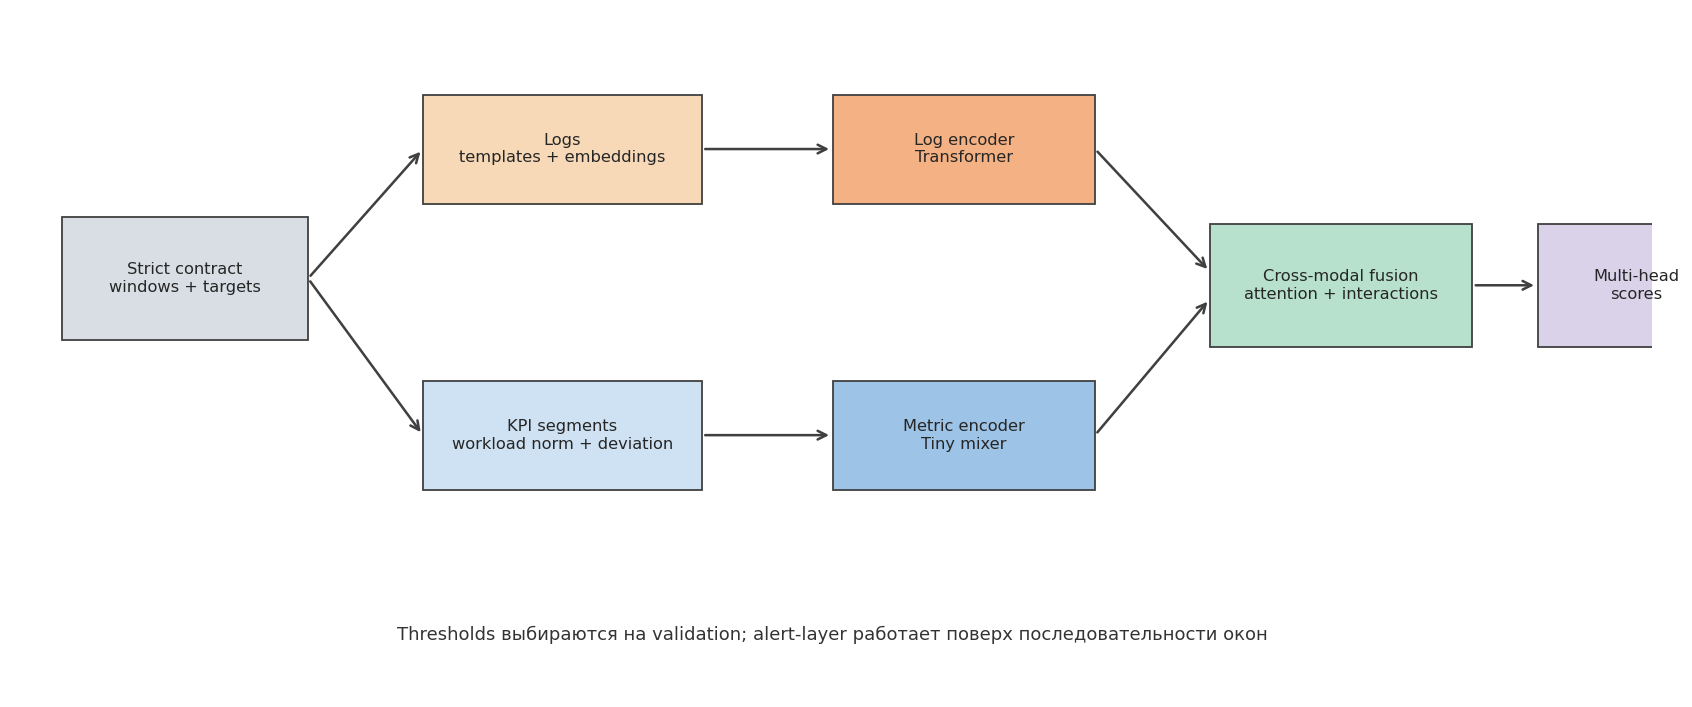

In [4]:
run_config = read_json(MODEL_DIR / "run_config.json")
feature_manifest_all = read_json(MODEL_DIR / "feature_manifest.json")
feature_manifest = feature_manifest_all.get(EXPERIMENT_CONFIG["split_protocol"], {})
metric_manifest = feature_manifest.get("metric", {})
log_manifest = feature_manifest.get("log", {}).get("fasttext_hash", {})
embedding_manifest = log_manifest.get("embedding", {})

architecture_table = pd.DataFrame(
    [
        (
            "Log encoder",
            f"{run_config.get('max_log_events', 32)} событий x {run_config.get('log_embedding_dim', 128)} dim",
            "Transformer branch",
            "событийный контекст окна",
        ),
        (
            "KPI encoder",
            f"{metric_manifest.get('segment_len', 64)} шагов x {metric_manifest.get('input_dim', 323)} признака",
            "TinyTimeMixer-like metric branch",
            "числовая динамика и отклонения KPI",
        ),
        (
            "Availability masks",
            "log_mask / metric_mask",
            "masked pooling",
            "устойчивость к пустым логам и неполным KPI-сегментам",
        ),
        (
            "Cross-modal fusion",
            "log_repr + metric_repr",
            "bidirectional attention",
            "взаимодействие событий и метрик",
        ),
        (
            "Shared representation",
            "[log, metric, |diff|, product]",
            "MLP",
            "общее состояние окна",
        ),
        (
            "Multi-head output",
            ", ".join(EXPERIMENT_CONFIG["targets"]),
            "7 binary heads",
            "разные AIOps-задачи в одном inference",
        ),
        (
            "Threshold / alert layer",
            "validation scores + sequence of windows",
            "outside neural net",
            "score превращается в warning-события",
        ),
    ],
    columns=["Компонент", "Вход", "Механизм", "Роль"],
)
display(architecture_table.style.hide(axis="index"))

fig, ax = plt.subplots(figsize=(13.2, 5.6))
ax.axis("off")

boxes = [
    (0.03, 0.52, 0.15, 0.18, "Strict contract\nwindows + targets", PALETTE["light_gray"]),
    (0.25, 0.72, 0.17, 0.16, "Logs\ntemplates + embeddings", "#F7D9B7"),
    (0.25, 0.30, 0.17, 0.16, "KPI segments\nworkload norm + deviation", "#CFE2F3"),
    (0.50, 0.72, 0.16, 0.16, "Log encoder\nTransformer", "#F4B183"),
    (0.50, 0.30, 0.16, 0.16, "Metric encoder\nTiny mixer", "#9DC3E6"),
    (0.73, 0.51, 0.16, 0.18, "Cross-modal fusion\nattention + interactions", "#B7E1CD"),
    (0.93, 0.51, 0.12, 0.18, "Multi-head\nscores", "#D9D2E9"),
]

for x, y, w, h, text, color in boxes:
    ax.add_patch(plt.Rectangle((x, y), w, h, facecolor=color, edgecolor="#404040", linewidth=1.0))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9)

arrows = [
    ((0.18, 0.61), (0.25, 0.80)),
    ((0.18, 0.61), (0.25, 0.38)),
    ((0.42, 0.80), (0.50, 0.80)),
    ((0.42, 0.38), (0.50, 0.38)),
    ((0.66, 0.80), (0.73, 0.62)),
    ((0.66, 0.38), (0.73, 0.58)),
    ((0.89, 0.60), (0.93, 0.60)),
]
for start, end in arrows:
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", lw=1.4, color="#404040"))

ax.text(0.50, 0.08, "Thresholds выбираются на validation; alert-layer работает поверх последовательности окон", ha="center", fontsize=10, color="#333333")
plt.tight_layout()
plt.show()


На схеме важно разделение ответственности. Нейросеть выдает score по нескольким heads, но не объявляет инцидент сама по себе. Threshold-layer переводит score в бинарное решение на уровне окна, а alert-layer уже решает, когда последовательность окон становится предупреждением. Это сохраняет главный AIOps-принцип работы: score модели, состояние alert-layer и факт incident не смешиваются.

Архитектура также объясняет слово `Efficient`. Здесь нет тяжелого языкового encoder в runtime: логовые события кодируются компактным hash/template embedding, KPI ограничены 64 выбранными каналами, `d_model=128`, log branch имеет 1 слой, metric branch - 2 слоя. Поэтому финальная модель должна быть не только точнее или аккуратнее baseline, но и пригоднее для запуска вне большой GPU-машины.


## 3. Режимы запуска notebook

Notebook поддерживает три режима. `reproduce_from_manifest` восстанавливает исследовательский отчет из уже сохраненного manifest/checkpoint. `smoke_test` нужен для быстрой проверки архитектуры и схем без тяжелого обучения. Полный запуск делается через `train_from_scratch`: notebook вызывает `dashboard.training.final_model`, обучает Efficient HADES, экспортирует bundle и пытается создать ONNX/INT8 runtime-файлы.

Чтобы запустить обучение на CUDA-машине, в первой code-ячейке нужно поменять только одну строку:

```python
EXECUTION_MODE = "train_from_scratch"
```

После этого выполнить `Run All`. Если нужен именно INT8 runtime, перед стартом должны импортироваться `onnx` и `onnxruntime`; иначе notebook остановится до тяжелого обучения и прямо скажет, какой пакет поставить.


In [5]:
mode_table = pd.DataFrame(
    [
        ("train_from_scratch", "обучить модель, экспортировать bundle и ONNX/INT8", "полный пересчет на CUDA-машине"),
        ("reproduce_from_manifest", "восстановить отчет из manifest/checkpoint", "основной режим чтения ВКР"),
        ("smoke_test", "проверить forward pass и схемы без обучения", "быстрая проверка notebook"),
    ],
    columns=["Режим", "Что делает", "Когда нужен"],
)
display(mode_table.style.hide(axis="index"))

training_command = build_training_command()
print("Текущий EXECUTION_MODE:", EXECUTION_MODE)

if EXECUTION_MODE == "train_from_scratch":
    assert_runtime_dependencies()
    run_command(training_command)
    refresh_artifact_metadata()
    print("Training finished. Artifacts were refreshed from MODEL_DIR and BUNDLE_DIR.")
elif EXECUTION_MODE == "smoke_test":
    print("Smoke mode: heavy training is skipped; architecture and artifact checks will run below.")
else:
    print("Reproduce mode: using saved manifest, checkpoint and metrics.")


Режим,Что делает,Когда нужен
train_from_scratch,"обучить модель, экспортировать bundle и ONNX/INT8",полный пересчет на CUDA-машине
reproduce_from_manifest,восстановить отчет из manifest/checkpoint,основной режим чтения ВКР
smoke_test,проверить forward pass и схемы без обучения,быстрая проверка notebook


Текущий EXECUTION_MODE: train_from_scratch


module,status,version
onnx,OK,1.21.0
onnxruntime,OK,1.25.1


[1/7] Loading strict contract: C:\Users\а\main\Diploma\dashboard\artifacts\contract\strict_intensity_contract.csv.gz
Rows: 2883; split protocols: ['stratified_by_workload']; targets: ['y_warning', 'y_risk', 'y_anomaly', 'horizon_30s', 'horizon_60s', 'horizon_120s', 'horizon_300s']
[2/7] Loading raw KPI frames
[3/7] Preparing protocol: stratified_by_workload
     split  rows  runs  workloads  y_warning_positives  y_warning_prevalence  y_risk_positives  y_risk_prevalence  y_anomaly_positives  y_anomaly_prevalence  horizon_30s_positives  horizon_30s_prevalence  horizon_60s_positives  horizon_60s_prevalence  horizon_120s_positives  horizon_120s_prevalence  horizon_300s_positives  horizon_300s_prevalence         split_protocol
     train  1776   138         16                  803              0.452140               168           0.094595                  803              0.452140                    168                0.094595                    386                0.217342                  

В текущем режиме notebook читает сохраненный manifest. Это не означает, что обучение “выключено”: параметры запуска, история по epoch, checkpoint, thresholds, тестовые метрики и runtime-слоты берутся из сохраненных artifacts. Если переключить `EXECUTION_MODE` на `train_from_scratch`, эта же страница становится оркестратором полного training/export цикла.

Для ONNX/INT8 важна отдельная проверка. Качество модели оценивается по Torch checkpoint, а ONNX/INT8 рассматривается как runtime-режим для слабого CPU-only железа. Поэтому после полного запуска ожидаются три promoted-файла:

```text
dashboard/artifacts/model/protocol_fixed_efficient_hades/model.pt
dashboard/artifacts/model/protocol_fixed_efficient_hades/model.onnx
dashboard/artifacts/model/protocol_fixed_efficient_hades/model.int8.onnx
```


## 4. Training protocol и manifest

Перед метриками фиксируем протокол обучения. Это нужно не для формальности, а чтобы понять, какой именно эксперимент сравнивается с baseline из `02`. Особенно важны `monitor_target=horizon_60s` и `train_monitor=fp_budget_f1`: checkpoint выбирается по раннему warning при ограничении FP, а не по последней эпохе и не по test.

В этом же протоколе фиксируется runtime-часть. `--quantization dynamic` не меняет исследовательскую модель и не должен улучшать F1; он нужен, чтобы после обучения получить облегченный ONNX/INT8 inference artifact и проверить пригодность контура для ноутбука/CPU-only запуска.


In [14]:
train_manifest = read_json(MODEL_DIR / "train_manifest.json", default=[])
final_training_manifest = read_json(MODEL_DIR / "final_training_manifest.json")
model_manifest = read_json(MODEL_DIR / "protocol_fixed_model_manifest.json")
runtime_report = final_training_manifest.get("export_report", {}).get("runtime", {}) or model_manifest.get("runtime", {})

protocol_rows = [
    ("Run id", run_config.get("run_id", EXPERIMENT_CONFIG["run_id"])),
    ("Split protocol", ", ".join(run_config.get("split_protocols", [EXPERIMENT_CONFIG["split_protocol"]]))),
    ("Variant", ", ".join(run_config.get("variants", [EXPERIMENT_CONFIG["variant"]]))),
    ("Seed", ", ".join(map(str, run_config.get("seeds", [EXPERIMENT_CONFIG["seed"]])))),
    ("Targets", ", ".join(run_config.get("targets", EXPERIMENT_CONFIG["targets"]))),
    ("Monitor target", run_config.get("monitor_target", EXPERIMENT_CONFIG["monitor_target"])),
    ("Train monitor", run_config.get("train_monitor", EXPERIMENT_CONFIG["train_monitor"])),
    ("Normalization", run_config.get("normalization", EXPERIMENT_CONFIG["normalization"])),
    ("Metric feature mode", run_config.get("metric_feature_mode", EXPERIMENT_CONFIG["metric_feature_mode"])),
    ("Epochs / patience", f"{run_config.get('epochs', EXPERIMENT_CONFIG['epochs'])} / {run_config.get('patience', EXPERIMENT_CONFIG['patience'])}"),
    ("Batch size", run_config.get("batch_size", EXPERIMENT_CONFIG["batch_size"])),
    ("Device in run", run_config.get("device", EXPERIMENT_CONFIG["device"])),
    ("FP budget", run_config.get("fp_budget", EXPERIMENT_CONFIG["fp_budget"])),
    ("Quantization", run_config.get("quantization", EXPERIMENT_CONFIG["quantization"])),
    ("Torch checkpoint", runtime_report.get("torch_state", {}).get("status", "n/a")),
    ("ONNX FP32", runtime_report.get("onnx_fp32", {}).get("status", "n/a")),
    ("ONNX INT8", runtime_report.get("onnx_int8", {}).get("status", "n/a")),
]
display(pd.DataFrame(protocol_rows, columns=["Параметр", "Значение"]).style.hide(axis="index"))

train_runs = pd.DataFrame(
    [
        {
            "split_protocol": item.get("split_protocol"),
            "variant": item.get("variant"),
            "seed": item.get("seed"),
            "best_epoch": item.get("best_epoch"),
            "best_monitor": item.get("best_monitor"),
            "monitor_target": item.get("monitor_target"),
            "train_monitor": item.get("train_monitor"),
            "history_epochs": len(item.get("history", [])),
        }
        for item in train_manifest
    ]
)
display(train_runs.style.hide(axis="index").format({"best_monitor": "{:.3f}"}))


Параметр,Значение
Run id,final_protocol_fixed_hades
Split protocol,stratified_by_workload
Variant,modern_metric
Seed,43
Targets,"y_warning, y_risk, y_anomaly, horizon_30s, horizon_60s, horizon_120s, horizon_300s"
Monitor target,horizon_60s
Train monitor,fp_budget_f1
Normalization,workload_norm
Metric feature mode,raw_plus_deviation
Epochs / patience,30 / 8


split_protocol,variant,seed,best_epoch,best_monitor,monitor_target,train_monitor,history_epochs
stratified_by_workload,modern_metric,43,8,0.570,horizon_60s,fp_budget_f1,16


Manifest фиксирует один promoted run: `stratified_by_workload / modern_metric / seed=43`. Лучшая эпоха - 8, лучший validation monitor для `horizon_60s` при FP-budget policy - около 0.570. Полной seed-stability в текущих artifacts нет, поэтому дальше мы не будем делать вид, что доказали устойчивость по seed. Утверждение этого notebook скромнее: для зафиксированного протокола и seed модель обучалась воспроизводимо, а ее ограничения явно видны в сравнении с baseline.


## 5. Совместимость checkpoint, архитектуры и prediction schema

До анализа качества проверяем, что notebook действительно работает с согласованной моделью: есть checkpoint, его можно загрузить в архитектуру, forward pass возвращает 7 heads, а replay/prediction таблицы содержат score и target для нужных задач. Это быстрый smoke test, который не заменяет обучение, но защищает от ситуации, когда графики строятся по несовместимым файлам.


In [7]:
checks = []

required_files = {
    "model.pt": MODEL_DIR / "model.pt",
    "run_config.json": MODEL_DIR / "run_config.json",
    "train_manifest.json": MODEL_DIR / "train_manifest.json",
    "comparison_metrics.csv": MODEL_DIR / "comparison_metrics.csv",
    "replay_bundle.csv.gz": MODEL_DIR / "replay_bundle.csv.gz",
    "alert_level_metrics.csv": MODEL_DIR / "alert_level_metrics.csv",
    "baseline metrics": BASELINE_DIR / "baseline_protocol_metrics.csv",
}
for name, path in required_files.items():
    checks.append({"Check": name, "Status": "OK" if path.exists() else "FAIL", "Факт": str(path.relative_to(PROJECT_ROOT)) if path.exists() else "missing"})

smoke_status = "not run"
smoke_fact = ""
try:
    import torch
    from torch.utils.data import DataLoader
    from dashboard.modeling.protocol_fixed_hades import MultiHeadCrossModalHades, ProtocolDataset

    checkpoint = torch.load(MODEL_DIR / "model.pt", map_location="cpu")
    target_names = checkpoint.get("target_names", EXPERIMENT_CONFIG["targets"])
    metric_input_dim = int(metric_manifest.get("input_dim", 323))
    log_input_dim = int(run_config.get("log_embedding_dim", 128))
    model = MultiHeadCrossModalHades(
        log_input_dim=log_input_dim,
        metric_input_dim=metric_input_dim,
        d_model=int(run_config.get("d_model", 128)),
        heads=int(run_config.get("heads", 4)),
        log_layers=int(run_config.get("log_layers", 1)),
        metric_layers=int(run_config.get("metric_layers", 2)),
        metric_encoder=checkpoint.get("spec", {}).get("metric_encoder", "tiny_time_mixer"),
        target_names=target_names,
    )
    missing, unexpected = model.load_state_dict(checkpoint["state_dict"], strict=False)
    arrays = {
        "log_emb": np.random.default_rng(43).normal(size=(4, int(run_config.get("max_log_events", 32)), log_input_dim)).astype("float32"),
        "log_mask": np.ones((4, int(run_config.get("max_log_events", 32))), dtype="float32"),
        "metric_seg": np.random.default_rng(44).normal(size=(4, int(metric_manifest.get("segment_len", 64)), metric_input_dim)).astype("float32"),
        "metric_mask": np.ones((4, int(metric_manifest.get("segment_len", 64))), dtype="float32"),
        "target_matrix": np.zeros((4, len(target_names)), dtype="float32"),
    }
    batch = next(iter(DataLoader(ProtocolDataset(arrays, range(4)), batch_size=2)))
    model.eval()
    with torch.no_grad():
        logits = model(batch["log_emb"], batch["log_mask"], batch["metric_seg"], batch["metric_mask"])
        scores = torch.sigmoid(logits)
    ok = logits.shape == (2, len(target_names)) and not missing and not unexpected
    smoke_status = "OK" if ok else "FAIL"
    smoke_fact = f"logits={tuple(logits.shape)}, score_range=({scores.min().item():.3f}, {scores.max().item():.3f}), missing={len(missing)}, unexpected={len(unexpected)}"
except Exception as exc:
    smoke_status = "FAIL"
    smoke_fact = f"{type(exc).__name__}: {exc}"

checks.append({"Check": "checkpoint forward pass", "Status": smoke_status, "Факт": smoke_fact})

replay_sample = read_csv(MODEL_DIR / "replay_bundle.csv.gz")
schema_cols = []
for target in EXPERIMENT_CONFIG["targets"]:
    schema_cols.extend([f"score_{target}", f"target_{target}"])
missing_schema = [col for col in schema_cols if col not in replay_sample.columns]
checks.append(
    {
        "Check": "prediction schema",
        "Status": "OK" if not missing_schema and not replay_sample.empty else "FAIL",
        "Факт": f"rows={len(replay_sample):,}; missing={missing_schema[:5]}",
    }
)

check_table = pd.DataFrame(checks)
display(
    check_table.style.hide(axis="index").apply(
        lambda col: ["color: #1F7A3A; font-weight: bold" if value == "OK" else "color: #B84A4A; font-weight: bold" for value in col]
        if col.name == "Status"
        else ["" for _ in col],
        axis=0,
    )
)

failed = check_table.loc[check_table["Status"].eq("FAIL")]
if not failed.empty:
    raise AssertionError("Model smoke checks failed: " + ", ".join(failed["Check"].tolist()))


C:\Users\а\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\nn\modules\transformer.py:508: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\NestedTensorImpl.cpp:182.)
  output = torch._nested_tensor_from_mask(


Check,Status,Факт
model.pt,OK,dashboard\artifacts\model\protocol_fixed_efficient_hades\model.pt
run_config.json,OK,dashboard\artifacts\model\protocol_fixed_efficient_hades\run_config.json
train_manifest.json,OK,dashboard\artifacts\model\protocol_fixed_efficient_hades\train_manifest.json
comparison_metrics.csv,OK,dashboard\artifacts\model\protocol_fixed_efficient_hades\comparison_metrics.csv
replay_bundle.csv.gz,OK,dashboard\artifacts\model\protocol_fixed_efficient_hades\replay_bundle.csv.gz
alert_level_metrics.csv,OK,dashboard\artifacts\model\protocol_fixed_efficient_hades\alert_level_metrics.csv
baseline metrics,OK,dashboard\artifacts\reports\protocol_fixed_baselines\baseline_protocol_metrics.csv
checkpoint forward pass,OK,"logits=(2, 7), score_range=(0.009, 0.605), missing=0, unexpected=0"
prediction schema,OK,rows=519; missing=[]


Smoke test подтверждает, что checkpoint совместим с архитектурой: модель принимает batch с log/KPI-входами и возвращает 7 score-heads. Это важно именно для исследовательского документа: дальше мы анализируем не произвольные CSV, а outputs модели, которую notebook может загрузить и прогнать хотя бы в легком forward pass.


## 6. Training dynamics

Теперь смотрим на процесс обучения. Для HADES важно не только то, что train loss падал. Если loss уменьшается, а validation monitor ухудшается, модель может просто переобучаться и становиться непригодной для предупреждений. Поэтому на графике одновременно показаны train loss, validation AP, validation best-F1 и validation FP-budget F1 по monitor target `horizon_60s`. Вертикальная линия отмечает epoch, выбранный checkpoint rule.


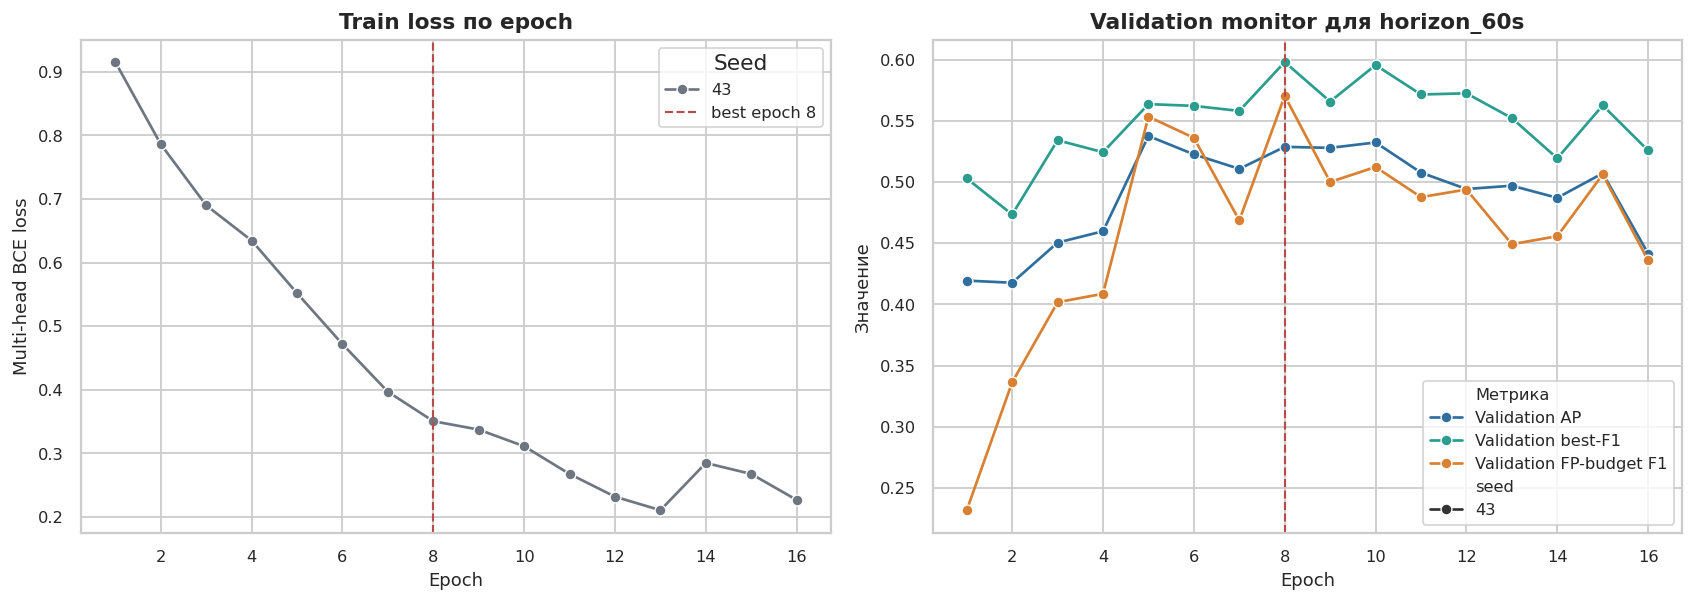

In [8]:
history_rows = []
for item in train_manifest:
    for row in item.get("history", []):
        history_rows.append(
            {
                "seed": item.get("seed"),
                "variant": item.get("variant"),
                "best_epoch": item.get("best_epoch"),
                **row,
            }
        )
history = pd.DataFrame(history_rows)

if history.empty:
    print("Training history is missing.")
else:
    best_epoch = int(history["best_epoch"].dropna().iloc[0])
    fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.8))
    sns.lineplot(data=history, x="epoch", y="train_loss", hue="seed", marker="o", palette=[PALETTE["gray"]], ax=axes[0])
    axes[0].axvline(best_epoch, color=PALETTE["red"], linestyle="--", linewidth=1.2, label=f"best epoch {best_epoch}")
    axes[0].set_title("Train loss по epoch")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Multi-head BCE loss")
    axes[0].legend(title="Seed")

    monitor_long = history.melt(
        id_vars=["epoch", "seed", "best_epoch"],
        value_vars=["val_ap", "val_best_f1", "val_fp_budget_f1"],
        var_name="Метрика",
        value_name="Значение",
    )
    monitor_long["Метрика"] = monitor_long["Метрика"].map(
        {
            "val_ap": "Validation AP",
            "val_best_f1": "Validation best-F1",
            "val_fp_budget_f1": "Validation FP-budget F1",
        }
    )
    sns.lineplot(
        data=monitor_long,
        x="epoch",
        y="Значение",
        hue="Метрика",
        style="seed",
        marker="o",
        palette=[PALETTE["blue"], PALETTE["teal"], PALETTE["orange"]],
        ax=axes[1],
    )
    axes[1].axvline(best_epoch, color=PALETTE["red"], linestyle="--", linewidth=1.2)
    axes[1].set_title("Validation monitor для horizon_60s")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Значение")
    axes[1].legend(title="")
    plt.tight_layout()
    plt.show()


На графике видно, что loss уверенно снижался: примерно с 0.915 на первой эпохе до 0.227 к последней сохраненной эпохе. Но validation-monitor не рос монотонно. Лучший checkpoint выбран на epoch 8, где `val_fp_budget_f1` достиг около 0.570. После этого train loss продолжал снижаться, а validation metrics колебались и местами ухудшались. Это хороший пример, почему checkpoint rule нужен формально: последняя эпоха не обязательно является лучшей моделью для alert-задачи.

Ограничение тоже видно прямо здесь: в artifacts есть только seed 43. Поэтому этот notebook не утверждает полную seed-stability. Для ВКР это честнее оставить как limitation, чем рисовать уверенность из одного запуска.


## 7. Сравнение с baseline: F1 и цена ошибок

Теперь сравниваем Efficient HADES с baseline из `02` на одном split protocol, target set и threshold policy. Важно не превращать таблицу в рекламный счет. Если baseline сильнее по F1, это остается в выводе. Если HADES снижает FP, но увеличивает FN, это называется trade-off, а не победа.


Target,baseline,f1_baseline,f1_hades,delta_f1,false_positives_baseline,false_positives_hades,delta_fp,missed_anomalies_baseline,missed_anomalies_hades,delta_fn,Verdict
120s,fused_log_metric,0.692,0.579,-0.113,134,65,-69,51,127,+76,"FP ниже, FN выше"
300s,metric_raw,0.846,0.682,-0.163,99,59,-40,23,142,+119,"FP ниже, FN выше"
30s,fused_log_metric,0.280,0.392,+0.112,158,60,-98,27,33,+6,HADES сильнее
60s,fused_log_metric,0.466,0.489,+0.023,172,97,-75,50,68,+18,"FP ниже, FN выше"
Предупреждение,log_tfidf,0.780,0.659,-0.121,140,69,-71,26,129,+103,"FP ниже, FN выше"
Риск,fused_log_metric,0.280,0.384,+0.104,158,59,-99,27,34,+7,HADES сильнее
Аномалия,log_tfidf,0.780,0.671,-0.109,140,72,-68,26,122,+96,"FP ниже, FN выше"


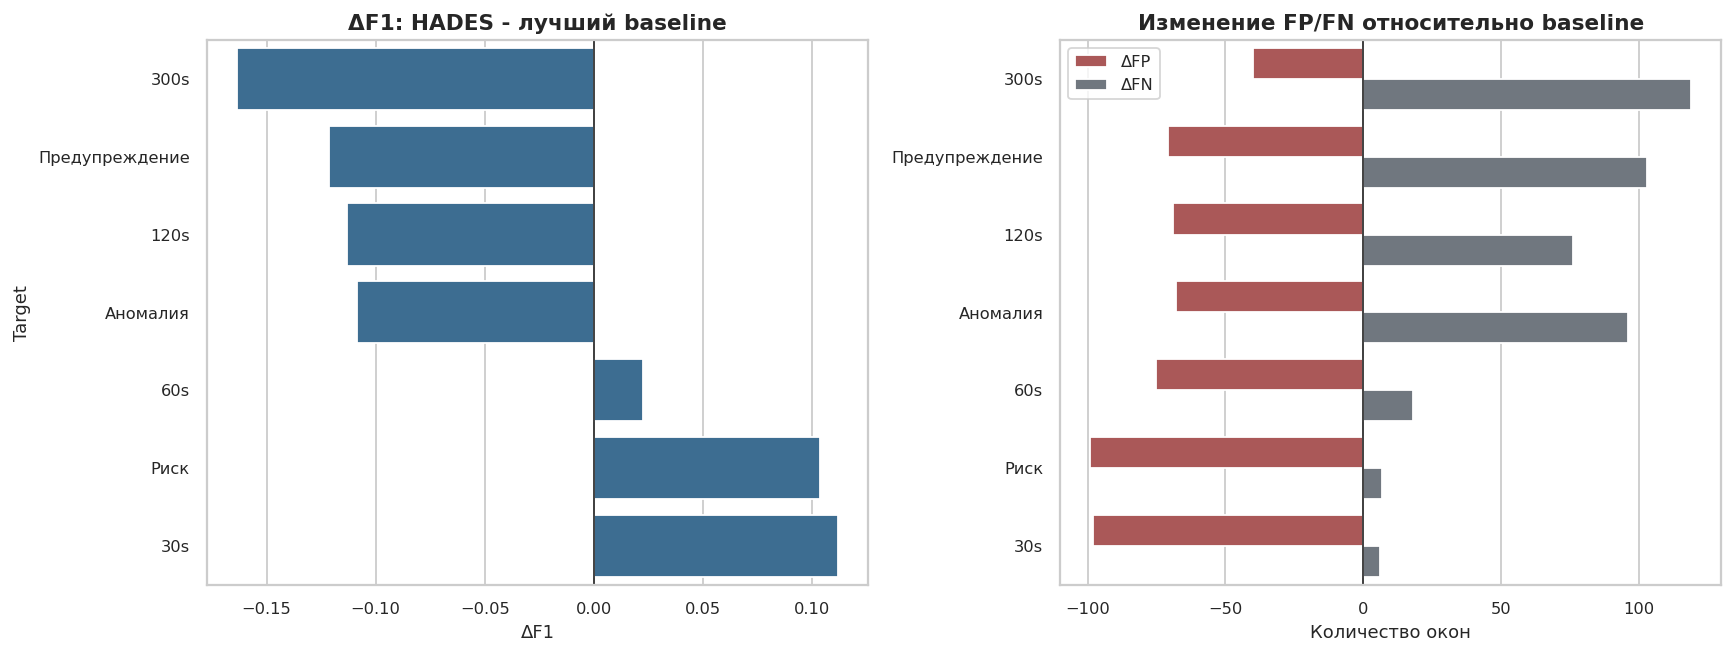

In [9]:
final_metrics = numeric(read_csv(MODEL_DIR / "comparison_metrics.csv"))
baseline_metrics = numeric(read_csv(BASELINE_DIR / "baseline_protocol_metrics.csv"))

final_test = final_metrics[
    final_metrics["split"].astype(str).eq("test")
    & final_metrics["threshold_policy"].astype(str).eq("validation_best_f1")
].copy()
baseline_test = baseline_metrics[
    baseline_metrics["split"].astype(str).eq("test")
    & baseline_metrics["threshold_policy"].astype(str).eq("validation_best_f1")
].copy()
best_baseline = (
    baseline_test.sort_values(["target", "f1", "average_precision"], ascending=[True, False, False])
    .groupby("target", as_index=False)
    .head(1)
)

comparison = final_test.merge(
    best_baseline[
        ["target", "baseline", "precision", "recall", "f1", "average_precision", "false_positives", "missed_anomalies"]
    ],
    on="target",
    suffixes=("_hades", "_baseline"),
)
comparison["Target"] = comparison["target"].map(label_target)
comparison["delta_f1"] = comparison["f1_hades"] - comparison["f1_baseline"]
comparison["delta_fp"] = comparison["false_positives_hades"] - comparison["false_positives_baseline"]
comparison["delta_fn"] = comparison["missed_anomalies_hades"] - comparison["missed_anomalies_baseline"]

def verdict(row: pd.Series) -> str:
    if row["delta_f1"] >= 0.05 and row["delta_fp"] <= 0:
        return "HADES сильнее"
    if row["delta_fp"] < 0 and row["delta_fn"] > 0:
        return "FP ниже, FN выше"
    if row["delta_f1"] > 0:
        return "умеренный выигрыш"
    return "baseline сильнее по F1"

comparison["Verdict"] = comparison.apply(verdict, axis=1)

display(
    comparison.sort_values("target")[
        [
            "Target",
            "baseline",
            "f1_baseline",
            "f1_hades",
            "delta_f1",
            "false_positives_baseline",
            "false_positives_hades",
            "delta_fp",
            "missed_anomalies_baseline",
            "missed_anomalies_hades",
            "delta_fn",
            "Verdict",
        ]
    ]
    .style.hide(axis="index")
    .format(
        {
            "f1_baseline": "{:.3f}",
            "f1_hades": "{:.3f}",
            "delta_f1": "{:+.3f}",
            "false_positives_baseline": "{:.0f}",
            "false_positives_hades": "{:.0f}",
            "delta_fp": "{:+.0f}",
            "missed_anomalies_baseline": "{:.0f}",
            "missed_anomalies_hades": "{:.0f}",
            "delta_fn": "{:+.0f}",
        }
    )
)

plot_order = comparison.sort_values("delta_f1")["Target"]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={"width_ratios": [1.0, 1.0]})
sns.barplot(data=comparison, y="Target", x="delta_f1", order=plot_order, color=PALETTE["blue"], ax=axes[0])
axes[0].axvline(0, color="#333333", linewidth=1)
axes[0].set_title("ΔF1: HADES - лучший baseline")
axes[0].set_xlabel("ΔF1")
axes[0].set_ylabel("Target")

error_plot = comparison.melt(
    id_vars=["Target"],
    value_vars=["delta_fp", "delta_fn"],
    var_name="Изменение",
    value_name="Окна",
)
error_plot["Изменение"] = error_plot["Изменение"].map({"delta_fp": "ΔFP", "delta_fn": "ΔFN"})
sns.barplot(
    data=error_plot,
    y="Target",
    x="Окна",
    hue="Изменение",
    order=plot_order,
    palette=[PALETTE["red"], PALETTE["gray"]],
    ax=axes[1],
)
axes[1].axvline(0, color="#333333", linewidth=1)
axes[1].set_title("Изменение FP/FN относительно baseline")
axes[1].set_xlabel("Количество окон")
axes[1].set_ylabel("")
axes[1].legend(title="")
plt.tight_layout()
plt.show()


Сравнение получилось честным и не рекламным. HADES явно помогает на short-risk части: `y_risk` и `horizon_30s` дают прирост F1 примерно на 0.10-0.11 и почти на сотню меньше FP. На `horizon_60s` выигрыш по F1 небольшой, около +0.023, но FP падают со 172 до 97. Это именно тот сценарий, где модель становится полезнее для AIOps: меньше ложных предупреждений на раннем канале.

Но HADES не доминирует везде. На `y_warning`, `y_anomaly`, `horizon_120s` и особенно `horizon_300s` лучший baseline имеет более высокий F1. Причина видна по error trade-off: HADES почти везде снижает FP, но платит ростом FN. Это означает, что модель стала осторожнее. Для alert-системы это может быть оправдано, но только если явно признать цену: часть предупреждений будет пропущена.


## 8. PR-кривая для `horizon_60s`

`horizon_60s` - главный мониторинг-канал обучения: он достаточно ранний, чтобы быть полезным, и достаточно шумный, чтобы проверять FP-control. Для него PR-кривая информативнее ROC-кривой, потому что администратор видит не абстрактный ROC-AUC, а конкретную цену поднятых тревог.


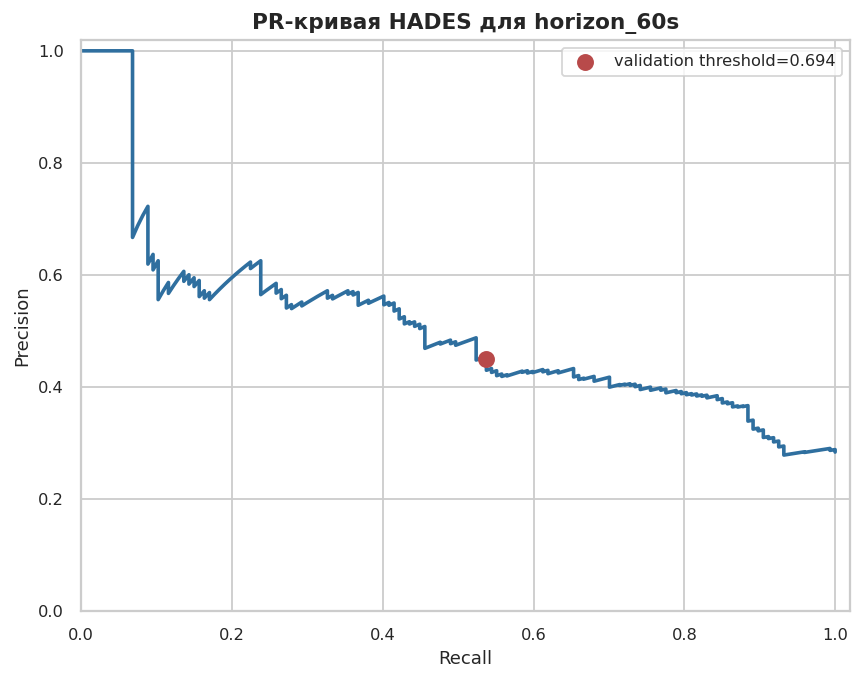

Target,Threshold,Precision@threshold,Recall@threshold,TP,FP,FN
60s,0.694,0.449,0.537,79,97,68


In [10]:
replay = read_csv(MODEL_DIR / "replay_bundle.csv.gz")
target = EXPERIMENT_CONFIG["monitor_target"]
score_col = f"score_{target}"
target_col = f"target_{target}"
threshold_col = f"threshold_{target}"

eval_replay = replay[replay.get("pred_split", replay.get("split")).astype(str).eq("test")].copy()
eval_replay = eval_replay[[score_col, target_col, threshold_col]].dropna()
y = eval_replay[target_col].astype(int).to_numpy()
score = eval_replay[score_col].astype(float).to_numpy()
threshold = float(eval_replay[threshold_col].dropna().iloc[0])

precision, recall, thresholds = precision_recall_curve(y, score)
pred = score >= threshold
tp = int(((pred == 1) & (y == 1)).sum())
fp = int(((pred == 1) & (y == 0)).sum())
fn = int(((pred == 0) & (y == 1)).sum())
thr_precision = tp / max(tp + fp, 1)
thr_recall = tp / max(tp + fn, 1)

fig, ax = plt.subplots(figsize=(6.8, 5.4))
ax.plot(recall, precision, color=PALETTE["blue"], linewidth=2)
ax.scatter([thr_recall], [thr_precision], color=PALETTE["red"], s=70, zorder=3, label=f"validation threshold={threshold:.3f}")
ax.set_title("PR-кривая HADES для horizon_60s")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.legend()
plt.tight_layout()
plt.show()

pr_point = pd.DataFrame(
    [
        {
            "Target": label_target(target),
            "Threshold": threshold,
            "Precision@threshold": thr_precision,
            "Recall@threshold": thr_recall,
            "TP": tp,
            "FP": fp,
            "FN": fn,
        }
    ]
)
display(pr_point.style.hide(axis="index").format({"Threshold": "{:.3f}", "Precision@threshold": "{:.3f}", "Recall@threshold": "{:.3f}"}))


PR-кривая показывает ограниченность раннего warning: область одновременно высокого precision и высокого recall небольшая. Validation threshold для `horizon_60s` стоит в компромиссной зоне: recall около 0.54, precision около 0.45. Это не “идеальный детектор”, но уже более управляемый канал, чем baseline smoke test: FP меньше, хотя часть positives уходит в FN.


## 9. Alert-layer: score превращается в предупреждение

Window-level score еще не является alert. В реальной AIOps-системе одиночный скачок score часто лучше не показывать пользователю как тревогу. Поэтому поверх score строится alert-layer: он требует несколько подряд подтверждающих окон и вводит cooldown. Это снижает шум, но может пропустить часть инцидентов.


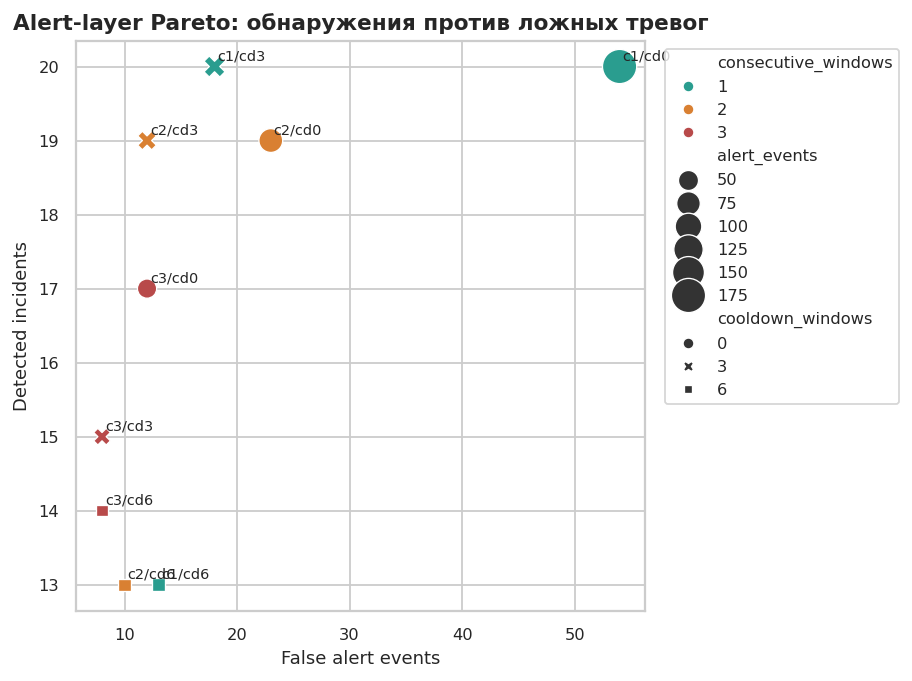

consecutive_windows,cooldown_windows,alert_events,false_alerts,detected_incidents,missed_incidents
3,3,30,8,15,16
3,6,27,8,14,17
2,6,32,10,13,18
2,3,41,12,19,12
3,0,45,12,17,14
1,6,40,13,13,18
1,3,57,18,20,11
2,0,77,23,19,12
1,0,176,54,20,11


In [11]:
alert = numeric(
    read_csv(MODEL_DIR / "alert_level_metrics.csv"),
    ["seed", "threshold", "consecutive_windows", "cooldown_windows", "alert_events", "false_alerts", "detected_incidents", "missed_incidents"],
)

fig, ax = plt.subplots(figsize=(7.2, 5.4))
sns.scatterplot(
    data=alert,
    x="false_alerts",
    y="detected_incidents",
    size="alert_events",
    hue="consecutive_windows",
    style="cooldown_windows",
    palette=[PALETTE["teal"], PALETTE["orange"], PALETTE["red"]],
    sizes=(80, 360),
    ax=ax,
)
for row in alert.itertuples(index=False):
    ax.text(row.false_alerts + 0.25, row.detected_incidents + 0.08, f"c{row.consecutive_windows}/cd{row.cooldown_windows}", fontsize=8)
ax.set_title("Alert-layer Pareto: обнаружения против ложных тревог")
ax.set_xlabel("False alert events")
ax.set_ylabel("Detected incidents")
ax.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

display(
    alert[["consecutive_windows", "cooldown_windows", "alert_events", "false_alerts", "detected_incidents", "missed_incidents"]]
    .sort_values(["false_alerts", "missed_incidents"])
    .style.hide(axis="index")
)


Pareto-график показывает, что alert-layer действительно меняет характер системы. При `consecutive=1, cooldown=0` модель обнаруживает 20 инцидентов, но создает 54 false alert events. Более строгая настройка `consecutive=3, cooldown=3` снижает false alerts до 8, но обнаруживает уже 15 инцидентов и пропускает 16. Это ровно та эксплуатационная развилка, которую нельзя увидеть по одному F1.

Для финального контура это означает: модель должна отдавать не только score, но и bundle с thresholds и alert-policy. Пользователь интерфейса должен видеть уже осмысленный alert-контур, а не сырую вероятность.


## 10. Workload errors: нормализованный разбор

Средняя метрика скрывает доменные проблемы. В `01` workload уже показали себя как важный источник различий, поэтому финальную модель нужно смотреть по workload. Здесь используется нормализованный разбор: FP rate, FN rate, precision и recall. Абсолютные counts не являются главным графиком, потому что крупные workload автоматически перетягивают внимание.


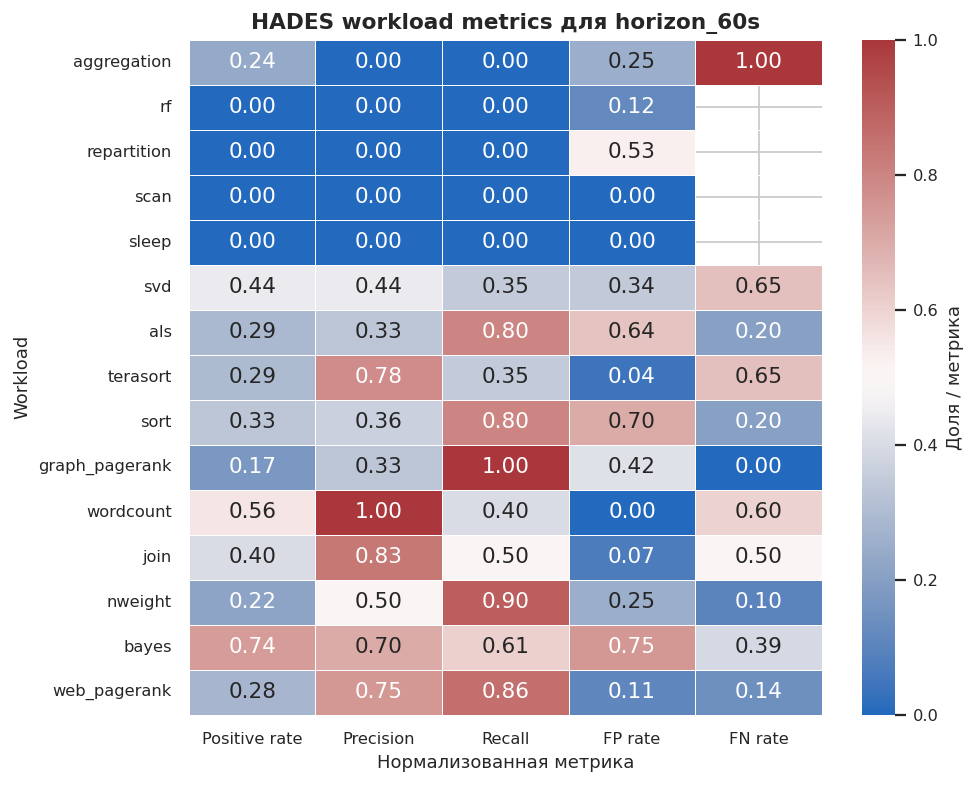

In [12]:
workload_metrics = numeric(read_csv(MODEL_DIR / "workload_metrics.csv"))
focus_target = EXPERIMENT_CONFIG["monitor_target"]
wm = workload_metrics[
    workload_metrics["target"].astype(str).eq(focus_target)
    & workload_metrics["seed"].astype(int).eq(int(EXPERIMENT_CONFIG["seed"]))
].copy()
wm = wm[wm["n"] >= 15].copy()
wm["negative_windows"] = (wm["n"] - wm["positives"]).replace(0, np.nan)
wm["positive_windows"] = wm["positives"].replace(0, np.nan)
wm["fp_rate"] = wm["false_positives"] / wm["negative_windows"]
wm["fn_rate"] = wm["missed_anomalies"] / wm["positive_windows"]
wm = wm.sort_values("f1")

work_heatmap = wm.set_index("workload")[["prevalence", "precision", "recall", "fp_rate", "fn_rate"]].rename(
    columns={
        "prevalence": "Positive rate",
        "precision": "Precision",
        "recall": "Recall",
        "fp_rate": "FP rate",
        "fn_rate": "FN rate",
    }
)

fig, ax = plt.subplots(figsize=(7.8, 6.2))
sns.heatmap(
    work_heatmap,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0.5,
    linewidths=0.45,
    linecolor="white",
    cbar_kws={"label": "Доля / метрика"},
    ax=ax,
)
ax.set_title("HADES workload metrics для horizon_60s")
ax.set_xlabel("Нормализованная метрика")
ax.set_ylabel("Workload")
plt.tight_layout()
plt.show()


Workload-разбор подтверждает, что ошибки распределены неравномерно. На некоторых workload positive-окон почти нет, и там FP rate становится главным риском. На других workload recall высокий, но precision падает. Это не просто “шум метрик”: для эксплуатации такая неоднородность означает, что интерфейс должен показывать уверенность и состояние alert-layer в контексте workload, а не только общий score.


## 11. Финальное решение по модели

Финальный verdict должен быть честным. Efficient HADES не является универсальным победителем по F1. Его ценность проявляется точнее: он снижает FP почти по всем target и особенно улучшает short-risk/early heads, но на длинных и более плотных задачах baseline остается сильным. Поэтому решение принимается не как “нейросеть победила”, а как “структурированный мультимодальный контур оправдан для раннего warning и runtime-bundle, но имеет ограничения”.


In [13]:
def reason(row: pd.Series) -> str:
    if row["Verdict"] == "HADES сильнее":
        return "рост F1 и резкое снижение FP на short-risk"
    if row["Verdict"] == "умеренный выигрыш":
        return "небольшой рост F1 и меньше FP"
    if row["Verdict"] == "FP ниже, FN выше":
        return "модель осторожнее: меньше шума, но больше пропусков"
    return "baseline лучше по F1/recall; HADES снижает FP ценой FN"

decision = comparison.sort_values("target")[["Target", "baseline", "f1_baseline", "f1_hades", "delta_f1", "delta_fp", "delta_fn", "Verdict"]].copy()
decision["Почему"] = comparison.apply(reason, axis=1)
display(
    decision
    .style.hide(axis="index")
    .format({"f1_baseline": "{:.3f}", "f1_hades": "{:.3f}", "delta_f1": "{:+.3f}", "delta_fp": "{:+.0f}", "delta_fn": "{:+.0f}"})
)

runtime_summary = pd.DataFrame(
    [
        ("Torch checkpoint", "available" if (MODEL_DIR / "model.pt").exists() else "missing"),
        ("Latency, ms/sample", f"{final_test['torch_latency_ms_per_sample'].dropna().iloc[0]:.4f}" if "torch_latency_ms_per_sample" in final_test and final_test["torch_latency_ms_per_sample"].notna().any() else "н/д"),
        ("ONNX/INT8", read_json(MODEL_DIR / "final_training_manifest.json").get("export_report", {}).get("runtime", {}).get("onnx_int8", {}).get("status", "reserved")),
        ("Replay bundle", "available" if (MODEL_DIR / "replay_bundle.csv.gz").exists() else "missing"),
        ("Alert events", "available" if (BUNDLE_DIR / "alert_events.csv").exists() else "missing"),
    ],
    columns=["Runtime artifact", "Status"],
)
display(runtime_summary.style.hide(axis="index"))


Target,baseline,f1_baseline,f1_hades,delta_f1,delta_fp,delta_fn,Verdict,Почему
120s,fused_log_metric,0.692,0.579,-0.113,-69,+76,"FP ниже, FN выше","модель осторожнее: меньше шума, но больше пропусков"
300s,metric_raw,0.846,0.682,-0.163,-40,+119,"FP ниже, FN выше","модель осторожнее: меньше шума, но больше пропусков"
30s,fused_log_metric,0.280,0.392,+0.112,-98,+6,HADES сильнее,рост F1 и резкое снижение FP на short-risk
60s,fused_log_metric,0.466,0.489,+0.023,-75,+18,"FP ниже, FN выше","модель осторожнее: меньше шума, но больше пропусков"
Предупреждение,log_tfidf,0.780,0.659,-0.121,-71,+103,"FP ниже, FN выше","модель осторожнее: меньше шума, но больше пропусков"
Риск,fused_log_metric,0.280,0.384,+0.104,-99,+7,HADES сильнее,рост F1 и резкое снижение FP на short-risk
Аномалия,log_tfidf,0.780,0.671,-0.109,-68,+96,"FP ниже, FN выше","модель осторожнее: меньше шума, но больше пропусков"


Runtime artifact,Status
Torch checkpoint,available
"Latency, ms/sample",0.0260
ONNX/INT8,available
Replay bundle,available
Alert events,available


## 12. Заключение

В этой части работы строился финальный мультимодальный контур раннего предупреждения, а не просто еще один классификатор для CSV. После `01` было понятно, что данные неоднородны и шумны. После `02` стало понятно, что pipeline работает и baseline извлекает сигнал, но ранние горизонты и FP остаются проблемой. `03` проверяет, помогает ли архитектурное усложнение решить именно эту прикладную часть.

Efficient HADES оказался полезен не как модель, которая выигрывает все target. Наоборот, сравнение показывает более сложную картину. Для `y_risk` и `horizon_30s` модель дает заметный прирост F1 и резко снижает FP. Для `horizon_60s` прирост F1 небольшой, но FP падают существенно, что важно для доверия к early-warning каналу. На `y_warning`, `y_anomaly`, `horizon_120s` и `horizon_300s` baseline по F1 сильнее, потому что HADES становится осторожнее и платит ростом FN.

С инженерной точки зрения модель все равно имеет ценность. Она объединяет logs и KPI в одном multi-head inference, использует workload-aware KPI normalization, строит отдельные heads для разных горизонтов, сохраняет thresholds и replay bundle, а alert-layer позволяет выбирать компромисс между detected incidents и false alerts. Это ближе к реальной AIOps-системе, чем одиночный baseline score.

Ограничения остаются существенными. Текущий promoted run содержит только seed 43, поэтому seed-stability надо усиливать отдельными запусками. Модель не калибрована как вероятность инцидента; ее score нужно трактовать как ранговый warning-signal. Alert-layer пока простой и требует дальнейшей настройки под эксплуатационные предпочтения. Наконец, baseline остается сильным на длинных горизонтах, и это нельзя скрывать.

Итоговый вывод для ВКР: Efficient HADES оправдан как финальный мультимодальный контур раннего предупреждения, если критерием считать не абсолютное доминирование по F1, а более системную ценность: ранний warning, снижение ложных тревог, единый multi-head output и готовность к runtime/replay bundle. Именно этот bundle затем может потребляться демонстрационным интерфейсом, но обучение, threshold selection и test metrics фиксируются здесь, в экспериментальном notebook.
